# 🚚 Delivery Logistics Multi-Partner Analysis
## An Exploratory Data Analysis and Business Intelligence Project

**Project focus:** Last-mile delivery performance, cost efficiency, partner reliability and customer experience  
**Dataset:** `Delivery_Logistics.csv`  
**Records:** 25,000 | **Attributes:** 15  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn and SciPy

---

## 🎯 The business story: What is happening inside our delivery network?

Imagine that we are part of the analytics team at a logistics company operating across several regions of India. The company works with multiple delivery partners and uses different vehicles and delivery modes.

Management has one central concern: **How can we make deliveries more reliable without allowing costs to rise unnecessarily?**

The dataset contains 25,000 delivery records. Each record describes a shipment, its partner, vehicle, route distance, package, weather conditions, delivery outcome, customer rating and cost.

Rather than creating charts without a purpose, we will investigate the business problem through five phases. Each phase will build on the previous one and lead us towards recommendations.

### The five-phase investigation

| Phase | Investigation | Management question |
|---|---|---|
| 1. Data foundation | Load, inspect and validate the data | Can we trust the data? |
| 2. Descriptive intelligence | Understand distributions and baselines | What does normal network performance look like? |
| 3. Pattern recognition | Compare partners, modes, vehicles, regions and weather | Where are the operational patterns and bottlenecks? |
| 4. Statistical deep dive | Test selected relationships | Which observed patterns have statistical evidence? |
| 5. Final briefing | Translate evidence into action | What should management do next? |

### Business questions we will answer

1. Which delivery partners handle the most shipments, and how do their delay, failure, cost and rating metrics compare?
2. Which weather conditions are associated with higher delay and failure rates?
3. How do distance, package weight and vehicle type relate to delivery cost?
4. Do delivery modes show different cost and outcome profiles?
5. How are delivery outcomes associated with customer ratings?
6. Do partner performance patterns change across regions?

> **A note about evidence:** This is observational data. A relationship between two columns does not prove that one caused the other. We will distinguish what the data shows from what we recommend investigating.

---

## 🧭 How to use this notebook

- Run cells from top to bottom.
- Read the Markdown explanation before running the code.
- Look at the output and charts before moving on.
- Try to explain each finding in your own words.
- The notebook includes learning notes explaining unfamiliar Pandas, plotting and statistics concepts.

**Suggested project folder:**

```text
Delivery_Logistics_TMP/
├── data/
│   └── Delivery_Logistics.csv
├── notebooks/
│   └── Delivery_Logistics_EDA.ipynb
├── presentation/
├── README.md
└── requirements.txt
```

# PHASE 1 — 🧱 Data Foundation & Quality Assessment

## 1.1 Before analysis: understand what each row represents

Our first task is not to make a chart. It is to understand the data we have received.

The dataset description says that each row represents a delivery. We will check whether the file structure supports that assumption, whether columns have usable data types, and whether records contain missing values or duplicates.

**Why this matters:** If delivery IDs are repeated unexpectedly, or time values are incorrectly encoded, our later KPIs may be misleading.

In [1]:
# Import the libraries used throughout the project.
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, spearmanr, kruskal

# A consistent visual theme makes charts easier to read.
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

print("Libraries imported successfully.")

Libraries imported successfully.


### 1.2 Load the delivery records

We will load the original CSV and preserve an untouched copy. Keeping the original data allows us to compare it with any cleaned or transformed version later.

**Learning note — `pd.read_csv()`** reads a CSV file into a Pandas DataFrame. A DataFrame is a two-dimensional table with rows and columns.

In [2]:
# Look for the dataset in common project locations.
candidate_paths = [
    Path("../data/Delivery_Logistics.csv"),
    Path("Delivery_Logistics.csv"),
    Path("/mnt/data/Delivery_Logistics.csv")
]

csv_path = next((path for path in candidate_paths if path.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        "Place Delivery_Logistics.csv in the data folder or beside this notebook."
    )

df_raw = pd.read_csv(csv_path)
df = df_raw.copy()

print(f"Dataset loaded from: {csv_path}")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
display(df.head())

Dataset loaded from: ../data/Delivery_Logistics.csv
Number of rows: 25,000
Number of columns: 15


,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250.990,delhivery,automobile parts,bike,same day,west,clear,297.000,46.960,1970-01-01 00:00:00.000000008,1970-01-01 00:00:00.000000008,no,delivered,3,"1,632.721"
1,250.990,xpressbees,cosmetics,ev van,express,central,cold,89.600,47.390,1970-01-01 00:00:00.000000002,1970-01-01 00:00:00.000000003,no,delivered,5,640.170
2,250.990,shadowfax,groceries,truck,two day,east,rainy,273.500,26.890,1970-01-01 00:00:00.000000010,1970-01-01 00:00:00.000000016,no,delivered,4,"1,448.170"
3,250.990,dhl,electronics,ev van,same day,east,cold,269.700,12.690,1970-01-01 00:00:00.000000006,1970-01-01 00:00:00.000000008,no,delivered,3,"1,486.570"
4,250.990,dhl,clothing,van,two day,north,foggy,256.700,37.020,1970-01-01 00:00:00.000000009,1970-01-01 00:00:00.000000016,no,delivered,4,"1,394.560"


### 1.3 First look: what information do we have?

The first five records help us see how the data is arranged. Next, we inspect dimensions, column names, data types and summary statistics.

**Learning note:**
- `shape` returns (rows, columns).
- `info()` shows data types and non-null counts.
- `describe()` summarizes numerical columns.
- `nunique()` counts distinct values in each column.

In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataFrame information:")
df.info()

print("\nNumerical summary:")
display(df.describe().T)

print("\nNumber of unique values in each column:")
display(df.nunique().to_frame("unique_values"))

Dataset shape: (25000, 15)

Column names:
['delivery_id', 'delivery_partner', 'package_type', 'vehicle_type', 'delivery_mode', 'region', 'weather_condition', 'distance_km', 'package_weight_kg', 'delivery_time_hours', 'expected_time_hours', 'delayed', 'delivery_status', 'delivery_rating', 'delivery_cost']

DataFrame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   delivery_id          25000 non-null  float64
 1   delivery_partner     25000 non-null  object 
 2   package_type         25000 non-null  object 
 3   vehicle_type         25000 non-null  object 
 4   delivery_mode        25000 non-null  object 
 5   region               25000 non-null  object 
 6   weather_condition    25000 non-null  object 
 7   distance_km          25000 non-null  float64
 8   package_weight_kg    25000 non-null  float64
 9   delive

,count,mean,std,min,25%,50%,75%,max
delivery_id,"25,000.000","12,500.500","7,212.732",250.990,"6,250.750","12,500.500","18,750.250","24,750.010"
distance_km,"25,000.000",150.390,86.410,3.600,75.900,151.000,224.900,297.100
package_weight_kg,"25,000.000",25.146,14.369,0.670,12.680,25.145,37.660,49.520
delivery_rating,"25,000.000",3.666,1.150,1.000,3.000,4.000,5.000,5.000
delivery_cost,"25,000.000",864.945,435.713,95.667,490.800,867.535,"1,237.910","1,632.721"



Number of unique values in each column:


,unique_values
delivery_id,24502
delivery_partner,9
package_type,9
vehicle_type,6
delivery_mode,4
region,5
weather_condition,6
distance_km,2935
package_weight_kg,4853
delivery_time_hours,20


### 1.4 Data dictionary: translate columns into business language

| Column | Business meaning | Expected role |
|---|---|---|
| `delivery_id` | Delivery record identifier | Identifier |
| `delivery_partner` | Company handling shipment | Category |
| `package_type` | Type of package | Category |
| `vehicle_type` | Vehicle used | Category |
| `delivery_mode` | Service speed / promise | Category |
| `region` | Broad delivery region | Category |
| `weather_condition` | Weather during delivery | Category |
| `distance_km` | Distance covered | Numeric |
| `package_weight_kg` | Package weight | Numeric |
| `delivery_time_hours` | Actual delivery duration | Intended numeric duration |
| `expected_time_hours` | Expected delivery duration | Intended numeric duration |
| `delayed` | Yes/no flag | Binary category |
| `delivery_status` | Delivered, delayed or failed | Outcome category |
| `delivery_rating` | Customer rating, 1–5 | Ordinal numeric |
| `delivery_cost` | Delivery cost | Numeric |

The next step is to compare the expected structure with the actual CSV.

### 1.5 Data quality audit: can we trust the raw file?

We will check four common data quality dimensions:

1. **Completeness:** Are values missing?
2. **Uniqueness:** Are there exact duplicate rows or repeated identifiers?
3. **Validity:** Are numeric values within plausible ranges?
4. **Consistency:** Do related columns agree with one another?

A repeated ID is not automatically a duplicate row. We must inspect it before deleting anything.

In [4]:
quality_report = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(quality_report)

exact_duplicates = df.duplicated().sum()
repeated_id_rows = df["delivery_id"].duplicated(keep=False).sum()
repeated_id_values = (df["delivery_id"].value_counts() > 1).sum()

print(f"Exact duplicate rows: {exact_duplicates}")
print(f"Rows whose delivery_id is repeated: {repeated_id_rows}")
print(f"Distinct delivery_id values repeated: {repeated_id_values}")
print("Most frequently repeated IDs:")
display(df["delivery_id"].value_counts().head())

,data_type,missing_values,missing_percent,unique_values
delivery_id,float64,0,0.000,24502
delivery_partner,object,0,0.000,9
package_type,object,0,0.000,9
vehicle_type,object,0,0.000,6
delivery_mode,object,0,0.000,4
region,object,0,0.000,5
weather_condition,object,0,0.000,6
distance_km,float64,0,0.000,2935
package_weight_kg,float64,0,0.000,4853
delivery_time_hours,object,0,0.000,20


Exact duplicate rows: 0
Rows whose delivery_id is repeated: 500
Distinct delivery_id values repeated: 2
Most frequently repeated IDs:


delivery_id
250.990       250
24,750.010    250
16,591.000      1
16,589.000      1
16,588.000      1
Name: count, dtype: int64

### 🔎 Data quality finding: the delivery identifier needs attention

The file contains **25,000 rows and no exact duplicate rows**, but it has **500 rows whose `delivery_id` is repeated**. Two identifier values (`250.99` and `24750.01`) each appear 250 times.

This means the identifier is not a reliable unique key in the supplied export. We will retain the rows for exploratory analysis because they are not exact duplicates, but we will not use `delivery_id` to remove records or assume it uniquely identifies a shipment.

**Business implication:** Before this dataset is used in a production reporting pipeline, the data owner should explain how delivery IDs were generated and why these two values repeat so frequently.

### 1.6 Inspect categories and numerical validity

Inconsistent labels such as `Yes`, `YES` and `yes` can accidentally create separate groups. We inspect category values before standardizing them.

We also look for impossible values such as negative distance, negative cost, zero package weight and ratings outside the 1–5 scale.

In [5]:
category_columns = [
    "delivery_partner", "package_type", "vehicle_type", "delivery_mode",
    "region", "weather_condition", "delayed", "delivery_status"
]

for column in category_columns:
    print(f"\n{column}: {sorted(df[column].dropna().astype(str).unique())}")

# Convert columns that should be numeric. Invalid text becomes NaN and can be reviewed.
for column in ["distance_km", "package_weight_kg", "delivery_rating", "delivery_cost"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

validity_checks = pd.Series({
    "Distance <= 0": (df["distance_km"] <= 0).sum(),
    "Package weight <= 0": (df["package_weight_kg"] <= 0).sum(),
    "Delivery cost < 0": (df["delivery_cost"] < 0).sum(),
    "Rating outside 1–5": (~df["delivery_rating"].between(1, 5)).sum()
}, name="records")
display(validity_checks.to_frame())


delivery_partner: ['amazon logistics', 'blue dart', 'delhivery', 'dhl', 'ecom express', 'ekart', 'fedex', 'shadowfax', 'xpressbees']

package_type: ['automobile parts', 'clothing', 'cosmetics', 'documents', 'electronics', 'fragile items', 'furniture', 'groceries', 'pharmacy']

vehicle_type: ['bike', 'ev bike', 'ev van', 'scooter', 'truck', 'van']

delivery_mode: ['express', 'same day', 'standard', 'two day']

region: ['central', 'east', 'north', 'south', 'west']

weather_condition: ['clear', 'cold', 'foggy', 'hot', 'rainy', 'stormy']

delayed: ['no', 'yes']

delivery_status: ['delayed', 'delivered', 'failed']


,records
Distance <= 0,0
Package weight <= 0,0
Delivery cost < 0,0
Rating outside 1–5,0


### 1.7 Investigate the unusual time columns

There is an important issue in the raw file: `delivery_time_hours` and `expected_time_hours` are stored as strings resembling timestamps, for example `1970-01-01 00:00:00.000000008`.

These are not ordinary numeric hour values. Parsing them as timestamps reveals tiny nanosecond offsets from the Unix epoch. The encoded integers appear to be the intended values, but the CSV itself does not prove that the integers represent hours.

We will therefore:
- preserve the original columns;
- extract the encoded integer into separate audit columns;
- label them as **encoded units**, not confirmed hours;
- avoid presenting time deviation or speed as verified operational metrics until the source owner confirms the units.

This is an example of why data validation must happen before business interpretation.

In [6]:
def extract_timestamp_offset(series):
    """Extract integer nanoseconds after the epoch from timestamp-like strings."""
    parsed = pd.to_datetime(series, errors="coerce")
    values = parsed.astype("int64").astype(float)
    values[parsed.isna()] = np.nan
    return values

# These are provisional encoded values, not yet confirmed hours.
df["actual_time_encoded"] = extract_timestamp_offset(df["delivery_time_hours"])
df["expected_time_encoded"] = extract_timestamp_offset(df["expected_time_hours"])

print("Raw actual-time values:")
display(df_raw["delivery_time_hours"].head())
print("Extracted actual-time encoding:")
display(df["actual_time_encoded"].describe().to_frame("encoded_value"))
print("Extracted expected-time encoding:")
display(df["expected_time_encoded"].describe().to_frame("encoded_value"))

Raw actual-time values:


0    1970-01-01 00:00:00.000000008
1    1970-01-01 00:00:00.000000002
2    1970-01-01 00:00:00.000000010
3    1970-01-01 00:00:00.000000006
4    1970-01-01 00:00:00.000000009
Name: delivery_time_hours, dtype: object

Extracted actual-time encoding:


,encoded_value
count,"25,000.000"
mean,6.248
std,3.141
min,0.000
25%,4.000
50%,6.000
75%,8.000
max,19.000


Extracted expected-time encoding:


,encoded_value
count,"25,000.000"
mean,13.108
std,7.559
min,2.000
25%,8.000
50%,8.000
75%,16.000
max,24.000


### 1.8 Consistency check: do the delay flag and delivery status agree?

The dataset contains two outcome fields:
- `delayed`: Yes or No
- `delivery_status`: Delivered, Delayed or Failed

We use a cross-tabulation to see how these fields relate. A cross-tabulation counts combinations of categories.

In [7]:
df["delayed_clean"] = df["delayed"].astype(str).str.strip().str.lower()
df["status_clean"] = df["delivery_status"].astype(str).str.strip().str.lower()

flag_status = pd.crosstab(df["delayed_clean"], df["status_clean"], margins=True)
display(flag_status)

status_clean,delayed,delivered,failed,All
delayed_clean,,,,
no,0,18331,0,18331
yes,5341,0,1328,6669
All,5341,18331,1328,25000


### 🔎 Data consistency finding: the delay flag includes failed deliveries

In this file, every `delayed = yes` record is either `delayed` or `failed` in `delivery_status`. Every `delayed = no` record is `delivered`.

Therefore, the `delayed` flag is broader than the delivery-status category named `delayed`.

For the rest of the notebook, we will report three separate measures:
- **Delay-flag rate:** `delayed == yes` (includes failed records in this dataset).
- **Delayed-status rate:** `delivery_status == delayed`.
- **Failure rate:** `delivery_status == failed`.

This prevents us from accidentally reporting a failure as a successful delivery or conflating two different outcomes.

### Phase 1 checkpoint — what did we learn about the data?

- The file contains 25,000 rows and 15 columns.
- There are no missing values and no exact duplicate rows.
- The delivery identifier is repeated in 500 rows and needs source-system clarification.
- The two time columns are timestamp-like encodings, not clean numeric durations.
- The delay flag includes failed deliveries, so delay and failure metrics must be reported separately.

**Decision:** We can proceed with descriptive analysis of the clean categorical and numeric fields, while keeping the time-unit limitation visible throughout the report.

# PHASE 2 — 📊 Descriptive Intelligence Gathering

## 2.1 Establish the operational baseline

Before comparing partners or vehicles, management needs a network-wide picture. We will calculate the total number of shipments, the mix of delivery outcomes, average delivery cost and customer ratings.

A KPI (Key Performance Indicator) is a measurable value used to monitor performance. These baseline KPIs will help us understand the overall scale and service quality of the network.

In [8]:
df["delay_flag"] = df["delayed_clean"].eq("yes").astype(int)
df["delayed_status_flag"] = df["status_clean"].eq("delayed").astype(int)
df["failed_flag"] = df["status_clean"].eq("failed").astype(int)
df["delivered_flag"] = df["status_clean"].eq("delivered").astype(int)
df["top_rating_flag"] = df["delivery_rating"].ge(4).astype(int)

baseline_kpis = pd.Series({
    "Total shipment records": len(df),
    "Distinct delivery IDs": df["delivery_id"].nunique(),
    "Average delivery cost": df["delivery_cost"].mean(),
    "Median delivery cost": df["delivery_cost"].median(),
    "Average customer rating": df["delivery_rating"].mean(),
    "Top ratings (4–5), %": df["top_rating_flag"].mean() * 100,
    "Delay-flag rate, %": df["delay_flag"].mean() * 100,
    "Delayed-status rate, %": df["delayed_status_flag"].mean() * 100,
    "Failure rate, %": df["failed_flag"].mean() * 100,
    "Delivered rate, %": df["delivered_flag"].mean() * 100
})
display(baseline_kpis.to_frame("value"))

,value
Total shipment records,"25,000.000"
Distinct delivery IDs,"24,502.000"
Average delivery cost,864.945
Median delivery cost,867.535
Average customer rating,3.666
"Top ratings (4–5), %",58.820
"Delay-flag rate, %",26.676
"Delayed-status rate, %",21.364
"Failure rate, %",5.312
"Delivered rate, %",73.324


### 2.2 What does the delivery outcome mix look like?

**Business question:** Out of all shipment records, how many were delivered, delayed or failed?

A count plot displays the number of records in each category. A percentage view is also useful because it communicates the size of each outcome relative to the whole network.

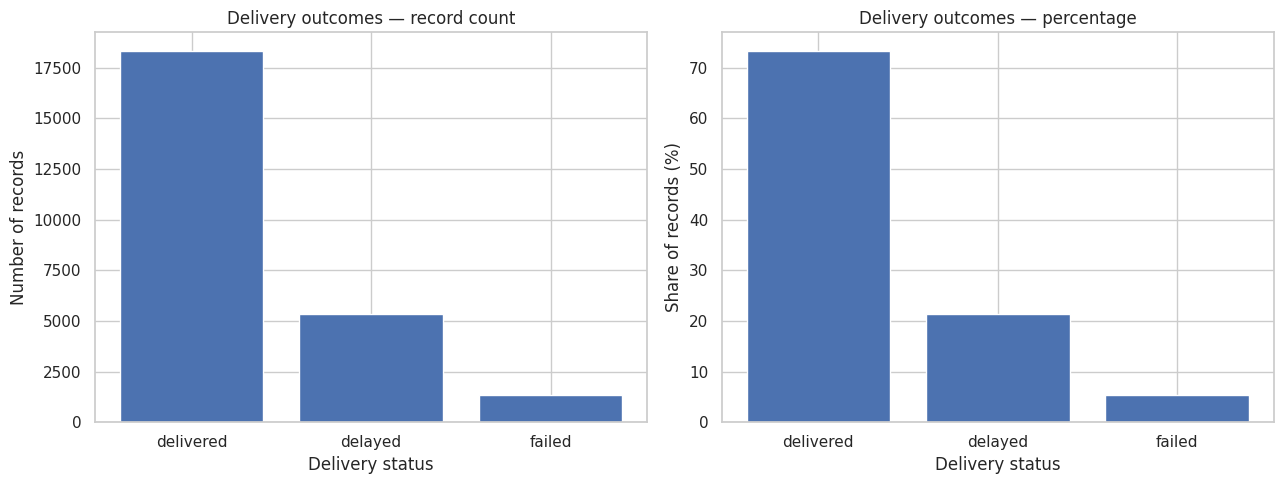

In [9]:
status_counts = df["status_clean"].value_counts().reindex(["delivered", "delayed", "failed"])
status_percent = status_counts / len(df) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(status_counts.index, status_counts.values)
axes[0].set_title("Delivery outcomes — record count")
axes[0].set_ylabel("Number of records")

axes[1].bar(status_percent.index, status_percent.values)
axes[1].set_title("Delivery outcomes — percentage")
axes[1].set_ylabel("Share of records (%)")
for ax in axes:
    ax.set_xlabel("Delivery status")
plt.tight_layout()
plt.show()

### 📌 Insight: roughly one in four records is not marked as delivered

The status distribution shows that **73.32%** of records are delivered, **21.36%** are delayed and **5.31%** are failed. Combining delayed and failed outcomes gives a delay-flag rate of **26.68%**.

**Why this matters:** A failure is more severe than a late delivery. Management should monitor delayed and failed shipments separately, while also tracking the broader delay flag as defined in this dataset.

### 2.3 How are delivery costs distributed?

**Business question:** Are most deliveries clustered around a typical cost, or are a small number of expensive shipments pulling the average upwards?

A histogram groups numerical values into ranges (bins). A boxplot summarizes the median, quartiles and potential extreme values.

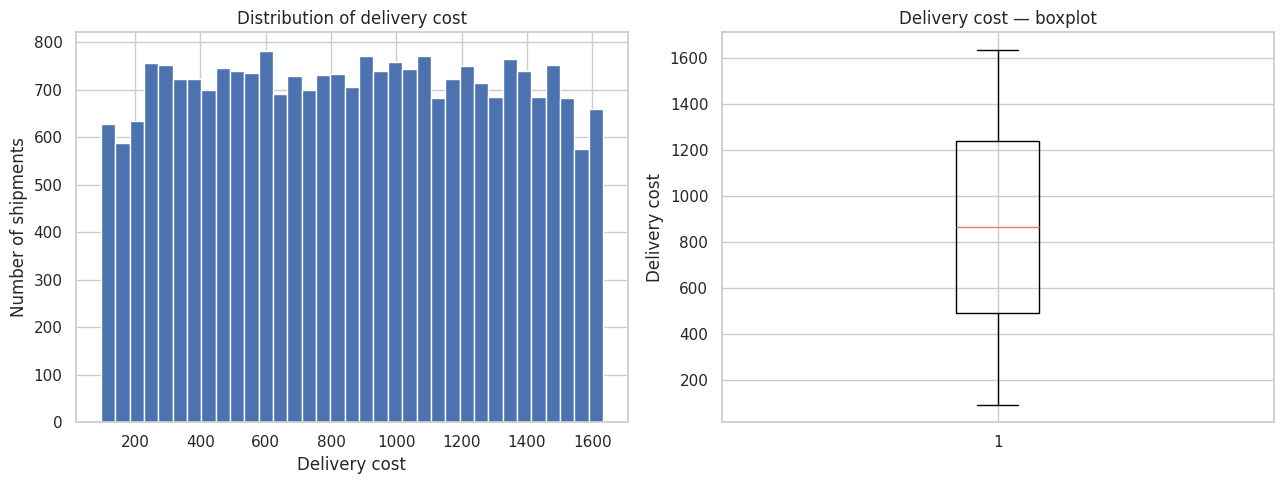

Mean cost: 864.94
Median cost: 867.54
Skewness: 0.001


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(df["delivery_cost"].dropna(), bins=35, edgecolor="white")
axes[0].set_title("Distribution of delivery cost")
axes[0].set_xlabel("Delivery cost")
axes[0].set_ylabel("Number of shipments")

axes[1].boxplot(df["delivery_cost"].dropna(), vert=True)
axes[1].set_title("Delivery cost — boxplot")
axes[1].set_ylabel("Delivery cost")
plt.tight_layout()
plt.show()

print("Mean cost:", round(df["delivery_cost"].mean(), 2))
print("Median cost:", round(df["delivery_cost"].median(), 2))
print("Skewness:", round(df["delivery_cost"].skew(), 3))

### 2.4 What distances and package weights are common?

**Business question:** Does this network mostly handle small/local shipments, or does it also handle heavy and long-distance consignments?

Histograms show the distribution of distance and weight. These variables matter because they are likely to be important cost drivers.

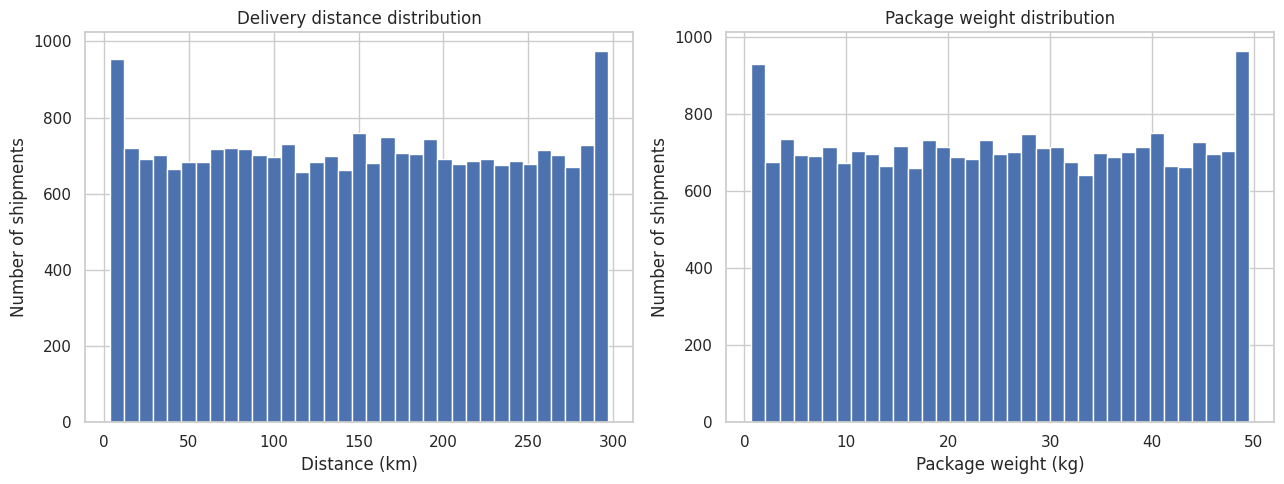

,count,mean,std,min,25%,50%,75%,max
distance_km,"25,000.000",150.390,86.410,3.600,75.900,151.000,224.900,297.100
package_weight_kg,"25,000.000",25.146,14.369,0.670,12.680,25.145,37.660,49.520


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(df["distance_km"].dropna(), bins=35, edgecolor="white")
axes[0].set_title("Delivery distance distribution")
axes[0].set_xlabel("Distance (km)")
axes[0].set_ylabel("Number of shipments")

axes[1].hist(df["package_weight_kg"].dropna(), bins=35, edgecolor="white")
axes[1].set_title("Package weight distribution")
axes[1].set_xlabel("Package weight (kg)")
axes[1].set_ylabel("Number of shipments")
plt.tight_layout()
plt.show()

display(df[["distance_km", "package_weight_kg"]].describe().T)

### 2.5 Which partners and service types handle the most shipments?

**Business question:** Is shipment volume concentrated among a few partners, or distributed evenly?

A bar chart is useful for comparing counts across categories. We also calculate market share as a percentage of all records.

,delivery_partner,shipments,market_share_pct
0,xpressbees,2826,11.304
1,fedex,2818,11.272
2,dhl,2802,11.208
3,ekart,2801,11.204
4,blue dart,2798,11.192
5,delhivery,2786,11.144
6,shadowfax,2736,10.944
7,ecom express,2722,10.888
8,amazon logistics,2711,10.844


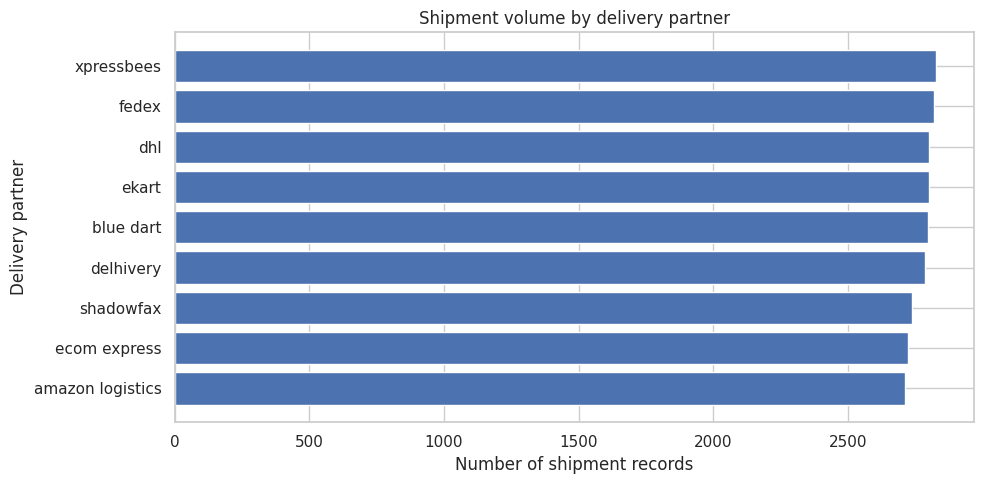

In [12]:
partner_volume = df["delivery_partner"].value_counts().rename_axis("delivery_partner").reset_index(name="shipments")
partner_volume["market_share_pct"] = partner_volume["shipments"] / len(df) * 100

display(partner_volume)

plt.figure(figsize=(10, 5))
plt.barh(partner_volume["delivery_partner"], partner_volume["shipments"])
plt.gca().invert_yaxis()
plt.title("Shipment volume by delivery partner")
plt.xlabel("Number of shipment records")
plt.ylabel("Delivery partner")
plt.tight_layout()
plt.show()

### Phase 2 checkpoint — the baseline story

Our first descriptive view establishes three important baselines:

- Delivery outcomes are not uniformly successful: about 26.7% of records carry the broader delay flag.
- Delivery cost, distance and package weight should be studied together rather than in isolation.
- Shipment volumes are spread across nine delivery partners, allowing partner-level comparisons.

The next phase moves from describing the network to identifying where differences appear.

# PHASE 3 — 🔍 Advanced Pattern Recognition

## 3.1 Partner performance: who appears more reliable?

**Management question:** Which delivery partners have lower delay and failure rates, and how do cost and customer ratings compare?

A partner with the lowest average cost is not automatically the best partner. We should compare reliability, customer experience, cost and sample size together.

We will group rows by partner and calculate multiple measures in one table. This is a common Pandas pattern: `groupby()` creates groups and `agg()` calculates summaries for each group.

In [13]:
partner_performance = df.groupby("delivery_partner").agg(
    shipments=("delivery_id", "size"),
    delay_flag_rate=("delay_flag", "mean"),
    delayed_status_rate=("delayed_status_flag", "mean"),
    failure_rate=("failed_flag", "mean"),
    average_cost=("delivery_cost", "mean"),
    median_cost=("delivery_cost", "median"),
    average_rating=("delivery_rating", "mean")
).reset_index()

for column in ["delay_flag_rate", "delayed_status_rate", "failure_rate"]:
    partner_performance[column] *= 100

partner_performance = partner_performance.sort_values("delay_flag_rate")
display(partner_performance.round(2))

,delivery_partner,shipments,delay_flag_rate,delayed_status_rate,failure_rate,average_cost,median_cost,average_rating
2,delhivery,2786,24.800,19.810,4.990,848.110,843.370,3.690
6,fedex,2818,25.160,20.400,4.760,857.360,855.390,3.700
3,dhl,2802,26.340,20.410,5.920,872.830,875.900,3.690
4,ecom express,2722,26.630,22.230,4.410,868.770,872.740,3.670
1,blue dart,2798,26.950,21.160,5.790,863.020,853.250,3.680
0,amazon logistics,2711,27.220,21.580,5.640,868.150,883.000,3.640
7,shadowfax,2736,27.300,22.440,4.860,868.340,871.960,3.660
5,ekart,2801,27.420,21.920,5.500,869.970,875.790,3.660
8,xpressbees,2826,28.270,22.360,5.910,868.170,884.920,3.610


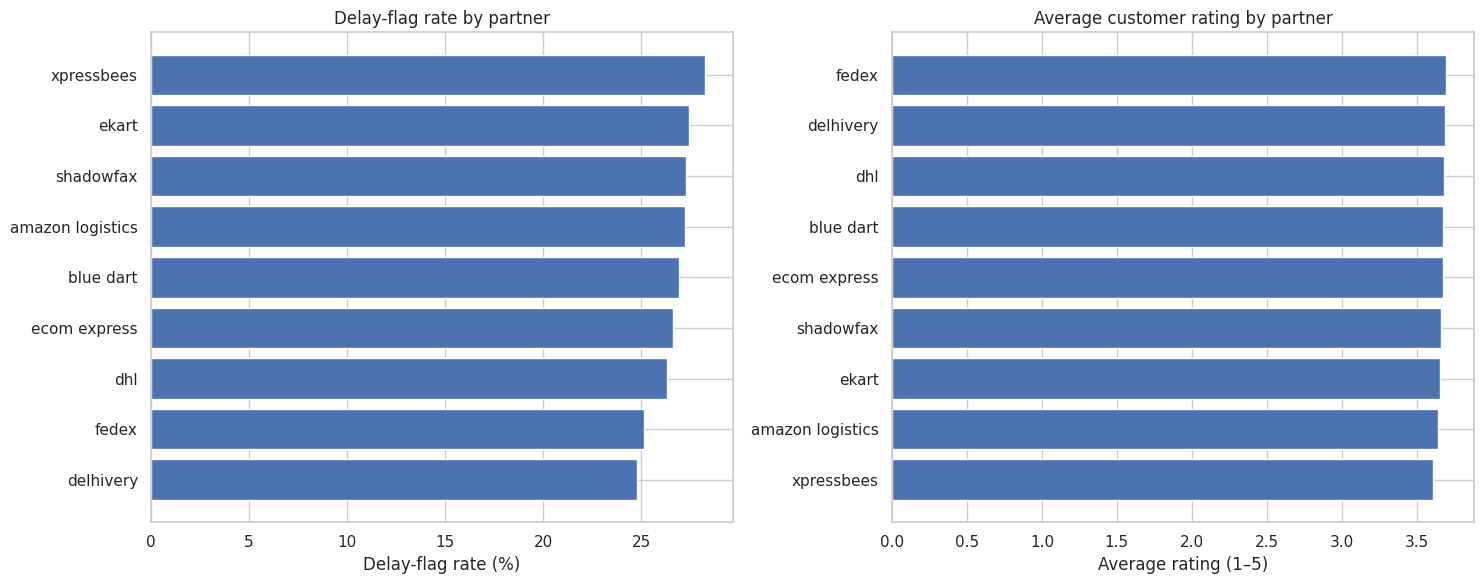

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].barh(partner_performance["delivery_partner"], partner_performance["delay_flag_rate"])
axes[0].set_title("Delay-flag rate by partner")
axes[0].set_xlabel("Delay-flag rate (%)")

rating_sorted = partner_performance.sort_values("average_rating")
axes[1].barh(rating_sorted["delivery_partner"], rating_sorted["average_rating"])
axes[1].set_title("Average customer rating by partner")
axes[1].set_xlabel("Average rating (1–5)")
plt.tight_layout()
plt.show()

### 📌 Insight: partner rankings are close, so avoid simplistic winner-takes-all conclusions

Delhivery has the lowest observed delay-flag rate at approximately **24.8%**, while XpressBees has the highest at approximately **28.3%**. Average customer ratings also vary within a relatively narrow range.

These are descriptive differences. Later, we will use a statistical test to check whether partner-level delivery-time and rating distributions differ enough to provide statistical evidence of a group effect.

**Business implication:** Use partner scorecards that show shipment count, delay rate, failure rate, average cost and rating together. Do not move large shipment volumes based on one percentage alone.

## 3.2 Weather and operational reliability

**Management question:** Which weather conditions are associated with higher delay and failure rates?

We calculate the proportion of shipments with each outcome inside every weather category. Comparing percentages is fairer than comparing raw counts when category sizes differ.

,weather_condition,shipments,delay_flag_rate,delayed_status_rate,failure_rate,average_cost,average_rating
5,stormy,4198,41.450,32.540,8.910,859.250,3.350
4,rainy,4171,37.350,29.970,7.380,867.470,3.470
2,foggy,4219,30.320,24.390,5.930,862.680,3.600
0,clear,4124,17.430,14.260,3.180,865.370,3.840
3,hot,4130,17.120,13.870,3.240,868.230,3.860
1,cold,4158,16.020,12.870,3.150,866.780,3.880


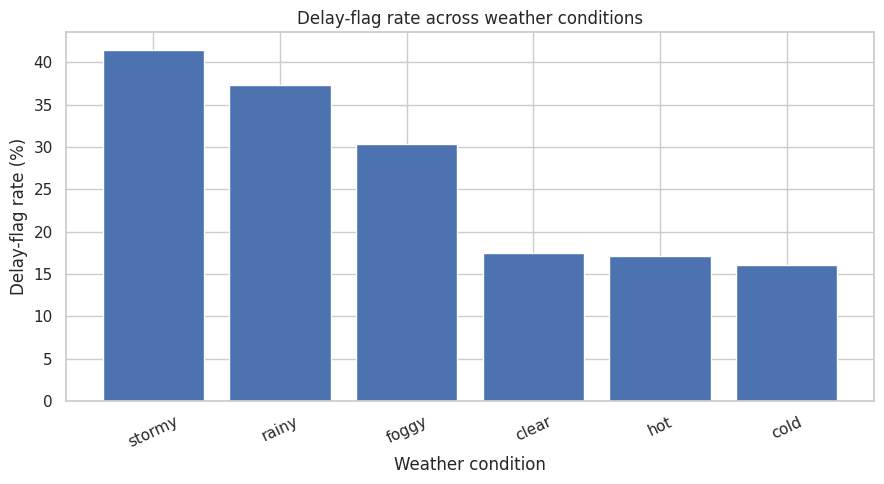

In [15]:
weather_performance = df.groupby("weather_condition").agg(
    shipments=("delivery_id", "size"),
    delay_flag_rate=("delay_flag", "mean"),
    delayed_status_rate=("delayed_status_flag", "mean"),
    failure_rate=("failed_flag", "mean"),
    average_cost=("delivery_cost", "mean"),
    average_rating=("delivery_rating", "mean")
).reset_index()

for column in ["delay_flag_rate", "delayed_status_rate", "failure_rate"]:
    weather_performance[column] *= 100

weather_performance = weather_performance.sort_values("delay_flag_rate", ascending=False)
display(weather_performance.round(2))

plt.figure(figsize=(9, 5))
plt.bar(weather_performance["weather_condition"], weather_performance["delay_flag_rate"])
plt.title("Delay-flag rate across weather conditions")
plt.xlabel("Weather condition")
plt.ylabel("Delay-flag rate (%)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

### 📌 Insight: stormy and rainy conditions are the highest-risk weather groups

Stormy conditions have a delay-flag rate of approximately **41.4%**, and rainy conditions approximately **37.4%**. By comparison, cold conditions are around **16.0%**.

The difference is large enough to deserve operational attention. However, weather may be related to region, route distance or vehicle choice, so we should not assume it is the only explanation.

**Business implication:** Test weather-aware delivery estimates, contingency capacity and proactive customer communication during adverse conditions. Validate the effect by region and vehicle before deploying a network-wide policy.

## 3.3 Delivery mode: are premium services delivering the promised experience?

**Management question:** Do Standard, Two Day, Same Day and Express shipments show different costs and outcome profiles?

We compare costs and the share of delivered, delayed and failed records by mode. This is particularly important because a premium mode should be evaluated not only by price, but also by whether its promised service is achieved.

,delivery_mode,shipments,average_cost,median_cost,delay_flag_rate,failure_rate,average_rating
0,express,6233,880.430,887.530,73.780,14.420,2.720
1,same day,6279,929.870,934.460,32.540,6.750,3.540
2,standard,6186,819.340,808.340,0.000,0.000,4.220
3,two day,6302,829.710,834.600,0.430,0.080,4.180


status_clean,delayed,delivered,failed
delivery_mode,,,
express,59.360,26.220,14.420
same day,25.780,67.460,6.750
standard,0.000,100.000,0.000
two day,0.350,99.570,0.080


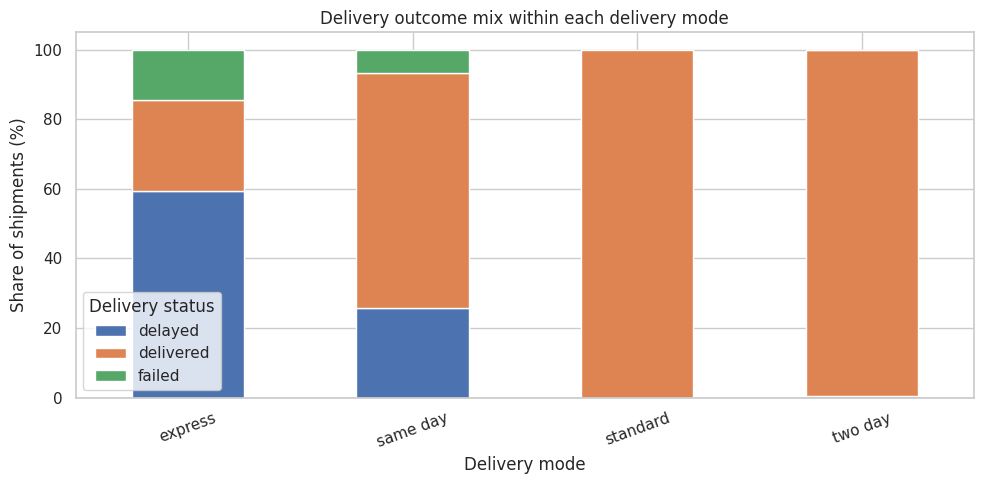

In [16]:
mode_performance = df.groupby("delivery_mode").agg(
    shipments=("delivery_id", "size"),
    average_cost=("delivery_cost", "mean"),
    median_cost=("delivery_cost", "median"),
    delay_flag_rate=("delay_flag", "mean"),
    failure_rate=("failed_flag", "mean"),
    average_rating=("delivery_rating", "mean")
).reset_index()
mode_performance["delay_flag_rate"] *= 100
mode_performance["failure_rate"] *= 100

display(mode_performance.round(2))

status_by_mode = pd.crosstab(
    df["delivery_mode"], df["status_clean"], normalize="index"
) * 100

display(status_by_mode.round(2))
status_by_mode.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Delivery outcome mix within each delivery mode")
plt.xlabel("Delivery mode")
plt.ylabel("Share of shipments (%)")
plt.xticks(rotation=20)
plt.legend(title="Delivery status")
plt.tight_layout()
plt.show()

### 🚩 Critical finding: Express and Standard show very different outcome patterns

In this dataset, Express has a delay-flag rate of approximately **73.8%**, while Standard has **0%** and Two Day is close to zero. Express also has a much higher failure share. Same Day sits between these groups.

This is an unusually strong separation. It may reflect the way service modes were assigned, the way outcomes were generated, or a genuine operational difference. The CSV alone cannot tell us which explanation is correct.

**Business implication:** Before recommending changes to Express capacity or pricing, management should audit the mode-specific SLA definitions, eligibility rules and status coding. If the pattern is confirmed operationally, Express needs a focused reliability review.

## 3.4 Vehicle type: which vehicle appears more cost-efficient?

**Management question:** Do average delivery costs and delay rates differ by vehicle type?

A simple group comparison is a useful first step, but it can be misleading if one vehicle serves heavier or longer-distance packages. We will inspect average cost, shipment count, distance, weight and delay rate together.

,vehicle_type,shipments,average_cost,average_distance,average_weight,delay_flag_rate,average_rating
0,bike,4160,868.920,151.420,25.010,27.040,3.650
1,ev bike,4218,869.240,151.040,25.430,26.430,3.670
2,ev van,4116,866.180,150.680,25.020,26.630,3.680
3,scooter,4174,862.910,150.160,24.630,26.140,3.680
4,truck,4145,864.770,150.270,25.410,27.040,3.670
5,van,4187,857.660,148.770,25.370,26.770,3.660


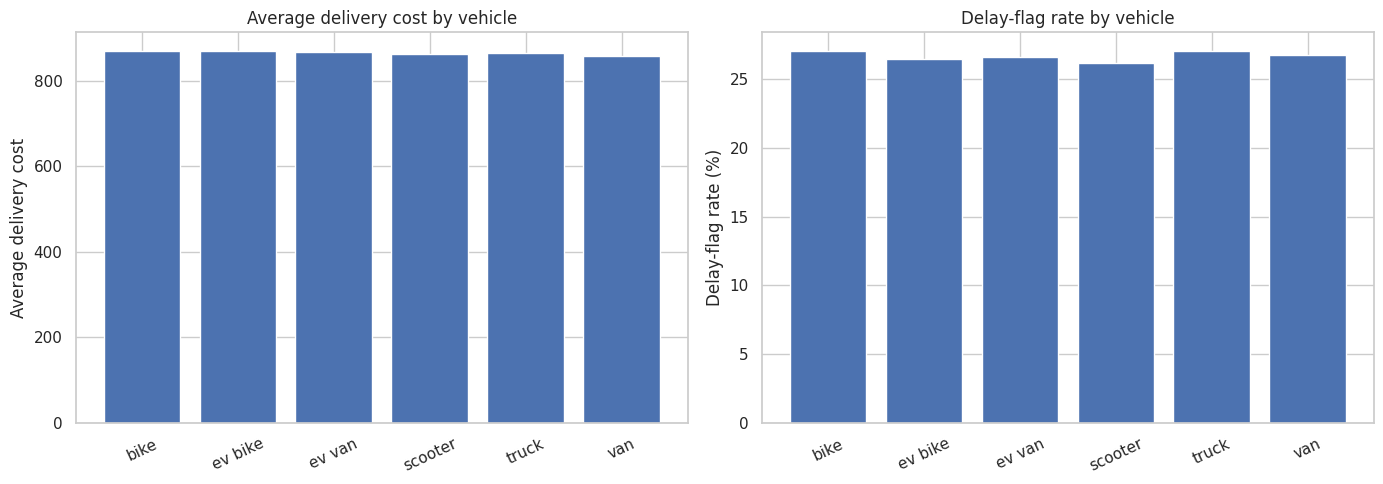

In [17]:
vehicle_performance = df.groupby("vehicle_type").agg(
    shipments=("delivery_id", "size"),
    average_cost=("delivery_cost", "mean"),
    average_distance=("distance_km", "mean"),
    average_weight=("package_weight_kg", "mean"),
    delay_flag_rate=("delay_flag", "mean"),
    average_rating=("delivery_rating", "mean")
).reset_index()
vehicle_performance["delay_flag_rate"] *= 100
display(vehicle_performance.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(vehicle_performance["vehicle_type"], vehicle_performance["average_cost"])
axes[0].set_title("Average delivery cost by vehicle")
axes[0].set_ylabel("Average delivery cost")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(vehicle_performance["vehicle_type"], vehicle_performance["delay_flag_rate"])
axes[1].set_title("Delay-flag rate by vehicle")
axes[1].set_ylabel("Delay-flag rate (%)")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

### 📌 Insight: vehicle averages are similar before adjusting for shipment mix

The unadjusted average costs across vehicle categories are relatively close compared with the differences observed across delivery modes. Average distance and package weight should be considered before declaring one vehicle the most efficient.

**Business implication:** Compare vehicles within similar distance, weight, region and delivery-mode groups. This is a more defensible way to identify where bikes, scooters, vans, trucks or EVs are economical.

## 3.5 Distance and delivery cost: does a longer route cost more?

**Management question:** Is distance associated with delivery cost?

We use a scatter plot to inspect the relationship and Spearman rank correlation to quantify whether higher distances tend to be associated with higher costs. Spearman correlation is useful when the relationship may not be perfectly linear or when extreme values are present.

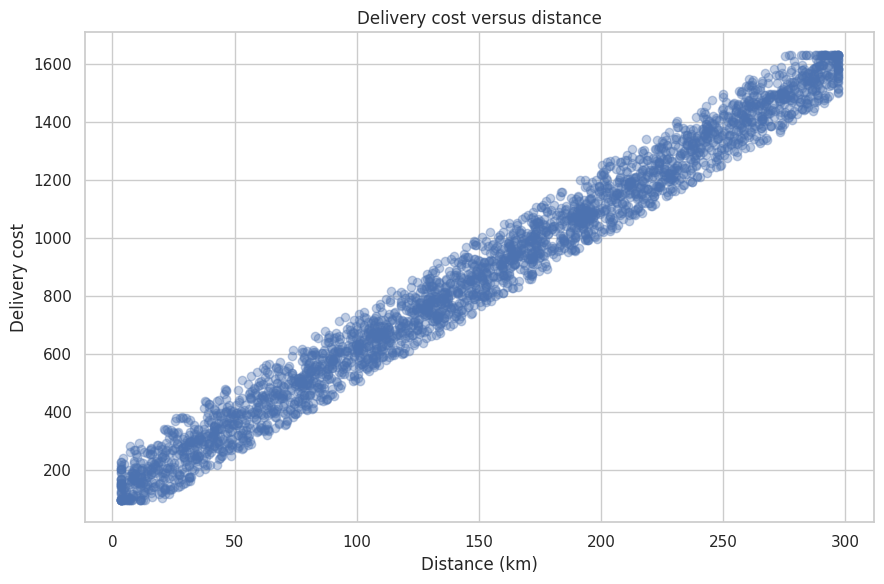

Spearman correlation: 0.991
P-value: 0


In [18]:
# Plot a reproducible sample so the chart remains readable.
plot_sample = df.sample(n=min(3000, len(df)), random_state=42)
plt.figure(figsize=(9, 6))
plt.scatter(plot_sample["distance_km"], plot_sample["delivery_cost"], alpha=0.35)
plt.title("Delivery cost versus distance")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery cost")
plt.tight_layout()
plt.show()

rho_distance_cost, p_distance_cost = spearmanr(
    df["distance_km"], df["delivery_cost"], nan_policy="omit"
)
print(f"Spearman correlation: {rho_distance_cost:.3f}")
print(f"P-value: {p_distance_cost:.4g}")

### 📌 Insight: distance and cost move together very strongly

The Spearman correlation between distance and delivery cost is approximately **0.991**, indicating a very strong positive monotonic association in this dataset.

**Business implication:** Distance is a key variable to include in cost benchmarking. A useful next step is to compare cost per kilometre by partner, vehicle and region, while also accounting for package weight and delivery mode.

## 3.6 Customer satisfaction: how do ratings differ by delivery outcome?

**Management question:** Are failed or delayed shipments associated with lower customer ratings?

We compare the rating distribution across delivery outcomes. The median is useful because ratings are ordinal and may not be normally distributed.

,shipment_count,average_rating,median_rating
status_clean,,,
delivered,18331,4.210,4.000
delayed,5341,2.400,2.000
failed,1328,1.310,1.000


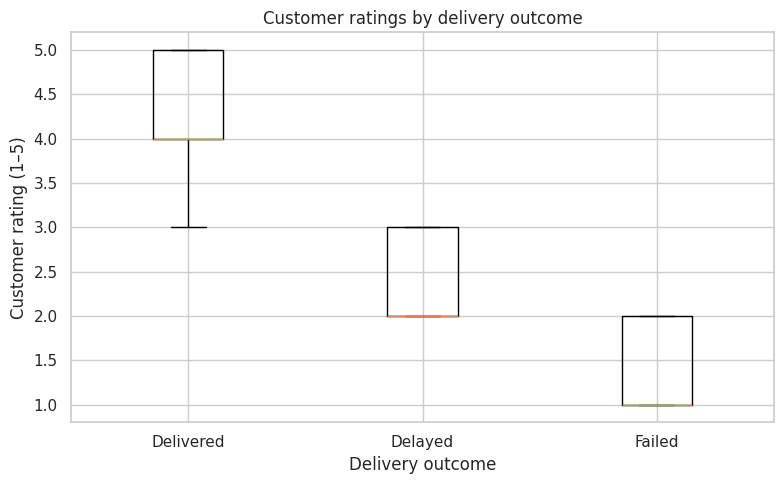

In [19]:
rating_by_status = df.groupby("status_clean")["delivery_rating"].agg(
    shipment_count="count", average_rating="mean", median_rating="median"
).sort_values("average_rating", ascending=False)
display(rating_by_status.round(2))

rating_groups = [
    df.loc[df["status_clean"] == status, "delivery_rating"].values
    for status in ["delivered", "delayed", "failed"]
]
plt.figure(figsize=(8, 5))
plt.boxplot(rating_groups, labels=["Delivered", "Delayed", "Failed"])
plt.title("Customer ratings by delivery outcome")
plt.xlabel("Delivery outcome")
plt.ylabel("Customer rating (1–5)")
plt.tight_layout()
plt.show()

### 📌 Insight: failed and delayed deliveries have lower customer ratings

Delivered records have an average rating of approximately **4.21**, delayed records approximately **2.40**, and failed records approximately **1.31**.

This is a strong descriptive relationship between delivery outcome and customer experience. It does not establish that delivery status is the only factor affecting ratings, but it clearly identifies service recovery as an important management priority.

**Business implication:** Prioritize customer communication and resolution for delayed and failed shipments. Track whether proactive updates and faster issue resolution improve ratings over time.

## 3.7 Multivariate view: partner performance across regions

**Management question:** Does a partner's delay rate change across regions?

A heatmap uses colour intensity to show values in a matrix. Here, rows are partners, columns are regions, and each cell is the delay-flag rate.

We will also show the number of shipments in each partner-region group. Small groups can produce unstable percentages.

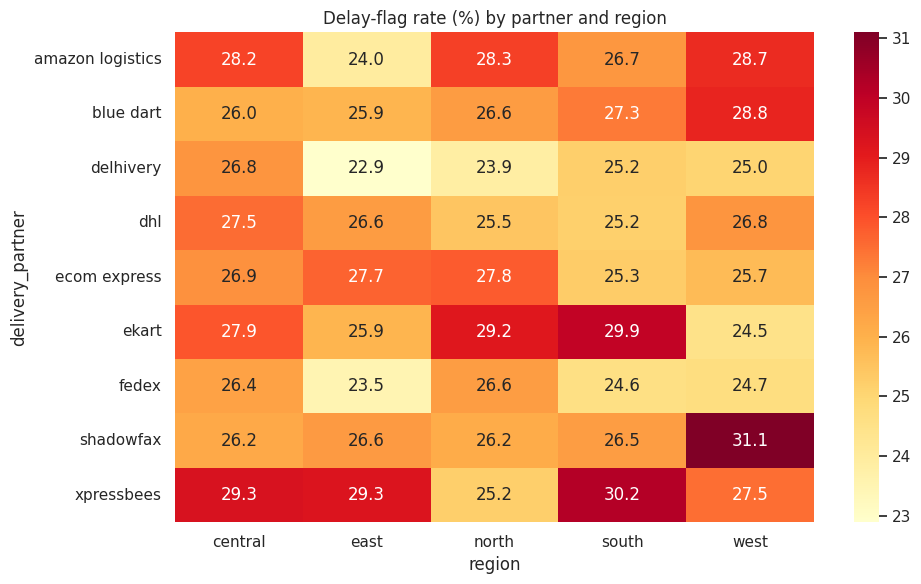

Shipment counts for each partner-region combination:


region,central,east,north,south,west
delivery_partner,,,,,
amazon logistics,549,513,541,554,554
blue dart,565,533,575,546,579
delhivery,590,546,528,563,559
dhl,596,583,522,556,545
ecom express,528,524,525,558,587
ekart,530,591,552,548,580
fedex,572,578,557,528,583
shadowfax,561,511,562,565,537
xpressbees,569,540,587,559,571


In [20]:
partner_region_rate = df.pivot_table(
    index="delivery_partner", columns="region",
    values="delay_flag", aggfunc="mean"
) * 100
partner_region_count = df.pivot_table(
    index="delivery_partner", columns="region",
    values="delivery_id", aggfunc="count"
)

plt.figure(figsize=(10, 6))
sns.heatmap(partner_region_rate, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Delay-flag rate (%) by partner and region")
plt.tight_layout()
plt.show()

print("Shipment counts for each partner-region combination:")
display(partner_region_count)

## 3.8 Multivariate view: vehicle and weather risk matrix

**Management question:** Are some vehicle-weather combinations associated with higher delay rates?

This matrix can help operations teams identify combinations worth investigating. It should not be interpreted as proof that a vehicle is unsuitable for a particular weather condition, because route distance, region and package mix may differ.

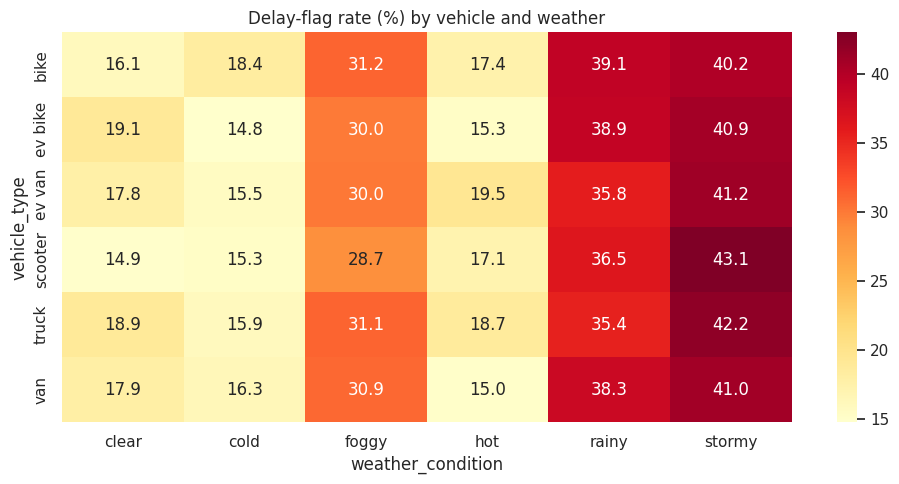

In [21]:
vehicle_weather_rate = df.pivot_table(
    index="vehicle_type", columns="weather_condition",
    values="delay_flag", aggfunc="mean"
) * 100

plt.figure(figsize=(10, 5))
sns.heatmap(vehicle_weather_rate, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Delay-flag rate (%) by vehicle and weather")
plt.tight_layout()
plt.show()

### Phase 3 checkpoint — where are the patterns?

The most actionable descriptive patterns so far are:

- Weather groups differ substantially in delay-flag rates.
- Express has an unusually high delayed/failed share compared with other modes; this requires a data-definition and operational audit.
- Distance and delivery cost have a very strong positive association.
- Customer ratings are much lower for delayed and failed records.
- Partner and vehicle comparisons need sample-size and shipment-mix context.

Next, we test selected relationships statistically. This helps distinguish a visible pattern from evidence of group association or distribution differences.

# PHASE 4 — 🧪 Statistical Deep Dive

## 4.1 Why do we need statistical tests?

A chart can show a difference, but it does not tell us whether that difference is likely to be more than random variation under a particular statistical model.

We will use a small set of tests that match our business questions:

| Business question | Test | What it examines |
|---|---|---|
| Is weather associated with the delay flag? | Chi-square test | Association between two categorical variables |
| Is delivery mode associated with outcome? | Chi-square test | Association between two categorical variables |
| Does distance move with cost? | Spearman correlation | Monotonic association between numeric variables |
| Do partner groups differ in delivery-time encoding or ratings? | Kruskal–Wallis | Difference in group distributions |

We use 0.05 as a conventional significance threshold. A small p-value does not measure business importance and does not prove causation.

## 4.2 Hypothesis 1 — Is weather associated with the delay flag?

- **Null hypothesis (H₀):** Weather condition and delay flag are independent.
- **Alternative hypothesis (H₁):** Weather condition and delay flag are associated.

The Chi-square test compares the observed category counts with the counts expected if the variables were independent.

In [22]:
weather_delay_table = pd.crosstab(df["weather_condition"], df["delayed_clean"])
chi2_weather, p_weather, dof_weather, expected_weather = chi2_contingency(weather_delay_table)

# Cramer's V gives an effect-size measure for a contingency table.
n = weather_delay_table.to_numpy().sum()
min_dimension = min(weather_delay_table.shape) - 1
cramers_v_weather = np.sqrt(chi2_weather / (n * min_dimension))

print("Observed counts:")
display(weather_delay_table)
print(f"Chi-square statistic: {chi2_weather:.2f}")
print(f"Degrees of freedom: {dof_weather}")
print(f"P-value: {p_weather:.4g}")
print(f"Cramer's V: {cramers_v_weather:.3f}")
print("Decision:", "Reject H0 at 5%" if p_weather < 0.05 else "Do not reject H0 at 5%")

Observed counts:


delayed_clean,no,yes
weather_condition,,
clear,3405,719
cold,3492,666
foggy,2940,1279
hot,3423,707
rainy,2613,1558
stormy,2458,1740


Chi-square statistic: 1354.46
Degrees of freedom: 5
P-value: 1.016e-290
Cramer's V: 0.233
Decision: Reject H0 at 5%


### Interpretation

The weather-delay association is statistically significant in this dataset (p-value far below 0.05). Cramer's V helps describe the strength of association, rather than relying on the p-value alone.

**Business reading:** The weather pattern is not merely a visual difference in this sample; the categorical variables are statistically associated. However, the test does not establish that weather alone caused the delays. Region, route and vehicle allocation may also matter.

## 4.3 Hypothesis 2 — Is delivery mode associated with delivery status?

- **H₀:** Delivery mode and delivery status are independent.
- **H₁:** Delivery mode and delivery status are associated.

This test is especially relevant because the descriptive analysis showed an unusually large outcome difference for Express deliveries.

In [23]:
mode_status_table = pd.crosstab(df["delivery_mode"], df["status_clean"])
chi2_mode, p_mode, dof_mode, expected_mode = chi2_contingency(mode_status_table)

n_mode = mode_status_table.to_numpy().sum()
cramers_v_mode = np.sqrt(chi2_mode / (n_mode * (min(mode_status_table.shape) - 1)))

display(mode_status_table)
print(f"Chi-square statistic: {chi2_mode:.2f}")
print(f"Degrees of freedom: {dof_mode}")
print(f"P-value: {p_mode:.4g}")
print(f"Cramer's V: {cramers_v_mode:.3f}")
print("Decision:", "Reject H0 at 5%" if p_mode < 0.05 else "Do not reject H0 at 5%")

status_clean,delayed,delivered,failed
delivery_mode,,,
express,3700,1634,899
same day,1619,4236,424
standard,0,6186,0
two day,22,6275,5


Chi-square statistic: 11654.49
Degrees of freedom: 6
P-value: 0
Cramer's V: 0.483
Decision: Reject H0 at 5%


### Interpretation

Delivery mode and delivery status are strongly associated in the supplied records. The size of the difference is also visible in the outcome table, especially for Express.

**Important:** Statistical significance cannot tell us whether the difference is caused by service design, allocation rules, operational capacity or synthetic/data-generation logic. This result should trigger a data and process audit before management changes service promises.

## 4.4 Hypothesis 3 — Does distance have a monotonic relationship with cost?

- **H₀:** There is no monotonic association between distance and delivery cost.
- **H₁:** A monotonic association exists.

Spearman's correlation coefficient ranges from -1 to +1. A value close to +1 means higher distances tend to occur with higher costs.

In [24]:
rho, p_rho = spearmanr(df["distance_km"], df["delivery_cost"], nan_policy="omit")
print(f"Spearman rho: {rho:.3f}")
print(f"P-value: {p_rho:.4g}")
print("Decision:", "Evidence of a monotonic association" if p_rho < 0.05 else "Insufficient evidence of association")

Spearman rho: 0.991
P-value: 0
Decision: Evidence of a monotonic association


### Interpretation

The correlation is approximately **0.991**, with a p-value below 0.001. Distance and cost have an extremely strong positive monotonic association in this dataset.

**Business reading:** Distance should be included in cost benchmarking. It is still important to include weight, vehicle, delivery mode and region in a more complete cost model.

## 4.5 Hypothesis 4 — Do delivery partners differ in time encoding and customer ratings?

We use the Kruskal–Wallis test, a non-parametric test that compares group distributions. It is useful when we do not want to assume that each group follows a normal distribution.

**Critical limitation:** The actual and expected time columns have not been confirmed as hours. We can compare the extracted numeric encodings as a data exploration exercise, but we must not interpret them as verified delivery-time performance until the data owner confirms the unit.

In [25]:
partner_time_groups = [
    group["actual_time_encoded"].dropna().values
    for _, group in df.groupby("delivery_partner")
]
partner_rating_groups = [
    group["delivery_rating"].dropna().values
    for _, group in df.groupby("delivery_partner")
]

h_time, p_time = kruskal(*partner_time_groups)
h_rating, p_rating = kruskal(*partner_rating_groups)

print(f"Partner groups — actual time encoding: H={h_time:.3f}, p={p_time:.4f}")
print("Interpretation:", "Group distributions differ" if p_time < 0.05 else "No statistically significant group difference detected")
print(f"Partner groups — customer rating: H={h_rating:.3f}, p={p_rating:.4f}")
print("Interpretation:", "Group distributions differ" if p_rating < 0.05 else "No statistically significant group difference detected")

Partner groups — actual time encoding: H=8.221, p=0.4122
Interpretation: No statistically significant group difference detected
Partner groups — customer rating: H=12.082, p=0.1476
Interpretation: No statistically significant group difference detected


### Interpretation

The partner-level Kruskal–Wallis tests do not find statistically significant differences at the 5% level for the extracted time encoding or customer ratings in this dataset.

This does not prove that all partners perform identically. It means that these tests do not provide sufficient evidence of group-distribution differences at the selected threshold. More detailed analysis could control for region, mode, distance and package mix.

## 4.6 Hypothesis 5 — Are delivery outcomes associated with customer ratings?

Ratings are ordinal scores from 1 to 5. We use Spearman correlation between the rating and a binary indicator for whether the delivery was successfully delivered. This is a compact association check; the group summary in Phase 3 remains the more intuitive business explanation.

In [26]:
rho_rating_outcome, p_rating_outcome = spearmanr(
    df["delivered_flag"], df["delivery_rating"], nan_policy="omit"
)
print(f"Spearman rho (delivered flag vs rating): {rho_rating_outcome:.3f}")
print(f"P-value: {p_rating_outcome:.4g}")

Spearman rho (delivered flag vs rating): 0.742
P-value: 0


### Phase 4 checkpoint — what has statistical support?

- Weather condition and delay flag are statistically associated.
- Delivery mode and delivery status are statistically associated; the unusually high Express delay/failure share deserves a data-definition audit.
- Distance and delivery cost have an extremely strong positive monotonic association.
- Partner-level rating distributions do not show statistically significant differences in the Kruskal–Wallis test.

Remember: statistical significance is not the same as causality, and p-values should be considered alongside effect size, sample size and operational context.

# PHASE 5 — 🎯 The Final Briefing: Business Recommendations

## 5.1 Executive summary

This analysis examined 25,000 delivery records across nine delivery partners, six vehicle types, four delivery modes, five regions and six weather categories.

The most important patterns are:

1. **Delivery outcomes:** 73.32% of records are delivered, 21.36% delayed and 5.31% failed. The broader delay flag is 26.68% because it includes failed records.
2. **Weather:** Stormy and rainy categories have the highest delay-flag rates (about 41.4% and 37.4%). Weather and delay flag are statistically associated.
3. **Cost:** Distance and delivery cost have a very strong positive Spearman association (about 0.991).
4. **Service mode:** Express has a strikingly higher delayed/failed share than other modes. This should be audited before operational action.
5. **Customer experience:** Average rating is about 3.67/5; delivered records have much higher average ratings than delayed or failed records.
6. **Partner comparisons:** Delhivery has the lowest observed delay-flag rate and XpressBees the highest, but partner-level rating/time tests do not show statistically significant group differences at 5%.

## 5.2 Recommendations: turn observations into action

A strong business recommendation has three parts: **evidence → business implication → action**.

| Priority | Evidence from this dataset | Recommended action | KPI to monitor |
|---|---|---|---|
| High | Stormy/rainy groups have higher delay-flag rates | Pilot weather-aware ETA buffers and contingency plans | Delay-flag rate by weather and region |
| High | Express has a very high delayed/failed share | Audit Express SLA, eligibility, allocation and status coding | Express delivered, delayed and failed shares |
| High | Delayed/failed outcomes have lower ratings | Improve proactive notifications and service recovery | Average rating and complaint resolution time |
| Medium | Distance and cost are strongly associated | Benchmark cost per km by partner, vehicle and region | Cost per km, adjusted for package weight |
| Medium | Partner delay rates vary modestly | Use a balanced partner scorecard and investigate regional differences | Delay rate, failure rate, cost, rating and shipment count |
| Medium | Vehicle averages are close before adjustment | Compare vehicle types for similar distance, weight and delivery mode | Cost and delay rate within comparable shipment groups |

These are recommendations for pilots and validation, not proof that the proposed interventions will cause a specific improvement.

## 5.3 Suggested management scorecard

The following metrics should be monitored regularly:

| Area | KPI | Why it matters |
|---|---|---|
| Volume | Shipment count and partner share | Understand workload allocation |
| Reliability | Delayed-status rate and failure rate | Separate late deliveries from failed deliveries |
| Customer | Average rating and share of 4–5 ratings | Monitor customer experience |
| Cost | Average cost and cost per km | Compare cost efficiency |
| Weather resilience | Delay/failure rate by weather | Prepare for high-risk operating conditions |
| Service promise | Mode-specific delivered/delayed/failed share | Check whether premium promises are being met |

Do not combine all outcomes into one score until the company agrees on definitions and weights. A transparent scorecard is easier to explain and audit.

## 5.4 Data limitations and questions for the data owner

A professional analyst should communicate what the dataset cannot answer as clearly as what it can answer.

1. **Time encoding:** Why are delivery-time values stored as timestamp-like strings with nanosecond offsets? Are the extracted integers truly hours?
2. **Repeated identifiers:** Why do `250.99` and `24750.01` each appear 250 times?
3. **Delay definition:** Is `delayed = yes` intentionally used for both delayed and failed shipments?
4. **Delivery-mode pattern:** Why does Standard show no delayed or failed records while Express has a much higher outcome risk?
5. **Cost units:** Are delivery costs in INR, and do they include fuel, taxes, surcharges or reverse logistics?
6. **SLA rules:** What is the contractual expected time for each delivery mode?
7. **Time-series analysis:** Is a timestamp or delivery date available in another source? The current 15-column file does not support weekday, monthly or seasonal analysis.
8. **Route detail:** Are city, pincode, route, traffic or hub fields available? These could help explain regional and distance effects.

### What we should not claim from this dataset

- We cannot identify monthly or seasonal trends without dates.
- We cannot prove weather causes delays from an observational cross-tabulation.
- We cannot declare a universally best vehicle without controlling for shipment mix.
- We cannot report verified delivery speed or time deviation until the time units are confirmed.
- We cannot treat the repeated delivery IDs as unique shipment identifiers.

## 5.5 Conclusion — what should management take away?

The EDA provides an initial operational picture of the delivery network. It highlights weather-related risk, a strong distance-cost relationship, a marked difference in delivery outcomes across service modes and a close association between delivery outcomes and customer ratings.

The most immediate management priorities are to investigate the unusually high Express delay/failure share, plan for adverse-weather conditions and improve the handling of delayed and failed shipments. Cost benchmarking should include distance and package weight, while partner and vehicle comparisons should account for shipment mix.

**The most important next step is data validation.** Confirm the time-field units, identifier logic, delay/status definitions and delivery-mode SLAs before using these findings for operational targets or financial decisions.

---

## 📚 Learning recap: concepts practiced in this project

| Concept | Where we used it |
|---|---|
| DataFrame inspection | `head()`, `shape`, `info()`, `describe()` |
| Data quality | `isna()`, `duplicated()`, `nunique()`, validity checks |
| Data transformation | `to_numeric()`, string standardization, feature flags |
| Group analysis | `groupby()` and `agg()` |
| Cross-tabulation | `pd.crosstab()` |
| Pivot tables | `pivot_table()` |
| Visualization | Histograms, bar charts, boxplots, scatter plots and heatmaps |
| Correlation | Spearman correlation |
| Hypothesis testing | Chi-square and Kruskal–Wallis tests |
| Business communication | Evidence, implication and recommendation |

## ✅ Final submission checklist

- [ ] Keep the original CSV in the `data/` folder.
- [ ] Save this notebook in the `notebooks/` folder.
- [ ] Run **Kernel → Restart & Run All**.
- [ ] Review the output of every code cell.
- [ ] Add your own explanation in the interpretation sections.
- [ ] Prepare presentation slides using the most useful charts and findings.
- [ ] Include the time-field and repeated-ID limitations in the README and presentation.
- [ ] Add `requirements.txt` and upload the project to GitHub.